# Predição de sobrevivência no Titanic com MLP

## Contexto do problema e dicionário de dados

Este estudo usa a base de treinamento da competição pública [Titanic - Machine Learning from Disaster](https://www.kaggle.com/competitions/titanic/data), do Kaggle. O objetivo demonstrativo é classificar se um passageiro sobreviveu (`Survived` = 1) ou não (`Survived` = 0), analisando características conhecidas no conjunto. O problema ilustra como atributos socioeconômicos e familiares se relacionam à sobrevivência; os dados históricos não são representativos para decisões atuais sobre pessoas.

O CSV local é uma cópia pública da base, mantida em [Data Science Dojo](https://github.com/datasciencedojo/datasets/blob/master/titanic.csv). As colunas de identificação e texto livre (`PassengerId`, `Name`, `Ticket`, `Cabin`) não entram no modelo.

| Coluna | Tipo | Significado |
|---|---|---|
| `Pclass` | Inteiro | Classe da passagem (1 = primeira, 2 = segunda, 3 = terceira) |
| `Sex` | Categórico | Sexo registrado do passageiro |
| `Age` | Numérico | Idade em anos |
| `SibSp` | Inteiro | Número de irmãos/cônjuges a bordo |
| `Parch` | Inteiro | Número de pais/filhos a bordo |
| `Fare` | Numérico | Tarifa paga em libras |
| `Embarked` | Categórico | Porto: Cherbourg (C), Queenstown (Q) ou Southampton (S) |
| `Survived` | Binário (alvo) | 0 = não sobreviveu; 1 = sobreviveu |

In [13]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, matthews_corrcoef
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = Path.cwd()
if not (ROOT / "data" / "titanic.csv").exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "titanic.csv"
MODEL_PATH = ROOT / "models" / "pipeline_rede_neural.joblib"
sns.set_theme(style="whitegrid")

## Análise exploratória resumida

In [14]:
df = pd.read_csv(DATA_PATH)
features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
target = "Survived"
dados = df[features + [target]].copy()

print(f"Dimensões da base completa: {df.shape}")
print(f"Dimensões dos atributos e alvo: {dados.shape}")
print("Valores ausentes por coluna:")
display(dados.isna().sum().to_frame("valores_ausentes"))
display(dados.head())

Dimensões da base completa: (891, 12)
Dimensões dos atributos e alvo: (891, 8)
Valores ausentes por coluna:


,valores_ausentes
Pclass,0
Sex,0
Age,177
SibSp,0
Parch,0
Fare,0
Embarked,2
Survived,0


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Survived
0,3,male,22.0,1,0,7.2500,S,0
1,1,female,38.0,1,0,71.2833,C,1
2,3,female,26.0,0,0,7.9250,S,1
3,1,female,35.0,1,0,53.1000,S,1
4,3,male,35.0,0,0,8.0500,S,0


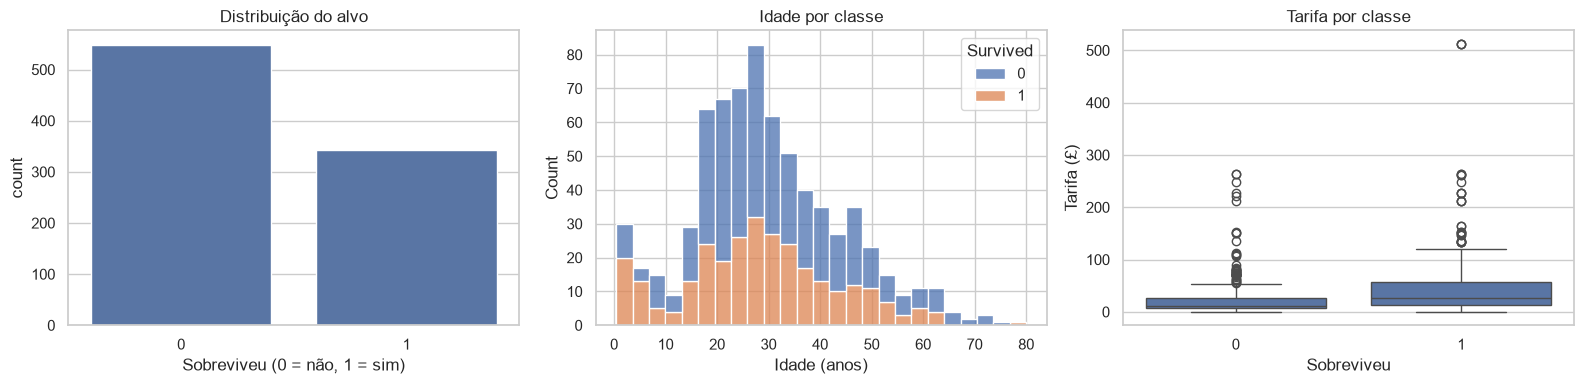

Proporção do alvo:


Survived
0    0.616162
1    0.383838
Name: proporcao, dtype: float64

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(data=dados, x=target, ax=axes[0])
axes[0].set(title="Distribuição do alvo", xlabel="Sobreviveu (0 = não, 1 = sim)")
sns.histplot(data=dados, x="Age", hue=target, bins=25, multiple="stack", ax=axes[1])
axes[1].set(title="Idade por classe", xlabel="Idade (anos)")
sns.boxplot(data=dados, x=target, y="Fare", ax=axes[2])
axes[2].set(title="Tarifa por classe", xlabel="Sobreviveu", ylabel="Tarifa (£)")
plt.tight_layout()
plt.show()

print("Proporção do alvo:")
display(dados[target].value_counts(normalize=True).sort_index().rename("proporcao"))

## Construção do pipeline Scikit-Learn

A divisão estratificada separa treino e teste antes do ajuste do pré-processamento. A imputação, padronização e codificação são aprendidas apenas no treino e ficam encapsuladas junto ao MLP no pipeline.

In [16]:
X = dados[features]
y = dados[target]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=77, stratify=y
)

numeric_features = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
categorical_features = ["Sex", "Embarked"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("mlp", MLPClassifier(
        hidden_layer_sizes=(128, 64, 32),
        learning_rate_init=0.001,
        random_state=77,
        max_iter=500,
        early_stopping=True,
        n_iter_no_change=25,
    )),
])

pipeline.fit(X_train, y_train)
print(f"Amostras de treino: {len(X_train)} | amostras de teste: {len(X_test)}")
print(f"Iterações do MLP: {pipeline.named_steps['mlp'].n_iter_}")

Amostras de treino: 712 | amostras de teste: 179
Iterações do MLP: 68


## Avaliação do modelo

As métricas abaixo são calculadas exclusivamente no conjunto de teste reservado. O relatório detalha precisão, revocação e F1 por classe; o coeficiente de Matthews resume o desempenho considerando todas as células da matriz de confusão.

Acurácia: 0.832
Matthews correlation coefficient: 0.641

Relatório de classificação:
                    precision    recall  f1-score   support

Não sobreviveu (0)       0.83      0.92      0.87       110
    Sobreviveu (1)       0.84      0.70      0.76        69

          accuracy                           0.83       179
         macro avg       0.83      0.81      0.82       179
      weighted avg       0.83      0.83      0.83       179



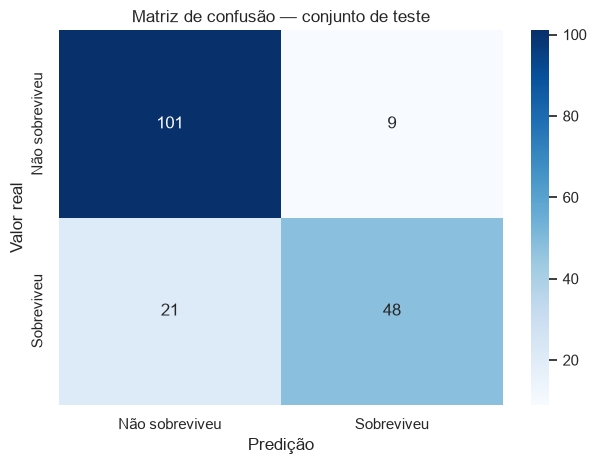

In [17]:
y_pred = pipeline.predict(X_test)
print(f"Acurácia: {accuracy_score(y_test, y_pred):.3f}")
print(f"Matthews correlation coefficient: {matthews_corrcoef(y_test, y_pred):.3f}")
print("\nRelatório de classificação:")
print(classification_report(
    y_test, y_pred,
    target_names=["Não sobreviveu (0)", "Sobreviveu (1)"],
    zero_division=0,
))

matriz = confusion_matrix(y_test, y_pred, labels=[0, 1])
sns.heatmap(
    matriz, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Não sobreviveu", "Sobreviveu"],
    yticklabels=["Não sobreviveu", "Sobreviveu"],
)
plt.xlabel("Predição")
plt.ylabel("Valor real")
plt.title("Matriz de confusão — conjunto de teste")
plt.tight_layout()
plt.show()

## Exportação do pipeline treinado

O artefato inclui imputadores, escalador, codificador e MLP. A API recebe os atributos brutos e reaplica automaticamente as transformações aprendidas somente no conjunto de treino.

In [18]:
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(pipeline, MODEL_PATH)
print(f"Pipeline salvo em: {MODEL_PATH.relative_to(ROOT)}")

Pipeline salvo em: models\pipeline_rede_neural.joblib
